
Flows discarded because Flow < 0.5 MAF: 32
Traces with a minimum flow: 2584
Ensemble sheets found: 22
Ensembles with at least one valid flow: 22

Sum of bars: 22 | Ensembles included: 22 | Ensemble sheets: 22

Ensemble agreement (each ensemble's lowest single-year flow):
  Bin  NumEnsembles
0   0             0
1   1             1
2   2             1
3   3             4
4   4             4
5   5            12

Trace-minimum counts per bin:
  Bin  NumTraceMinimums
0   0                 0
1   1                 1
2   2                43
3   3               156
4   4               379
5   5              1744

Lowest valid flow overall: 1.115 MAF (AR1, trace63, year 25.0)

Saved to:
C:\Users\Fager\Box\LakeMeadAnalysis\Low\Results\LowestFlowYear_ByTrace.csv
C:\Users\Fager\Box\LakeMeadAnalysis\Low\Results\LowestFlowYear_ByEnsemble.csv
C:\Users\Fager\Box\LakeMeadAnalysis\Low\Results\EnsembleAgreement_LowestFlowYear.csv
C:\Users\Fager\Box\LakeMeadAnalysis\Low\Results\Counts_LowestFlowYear.csv



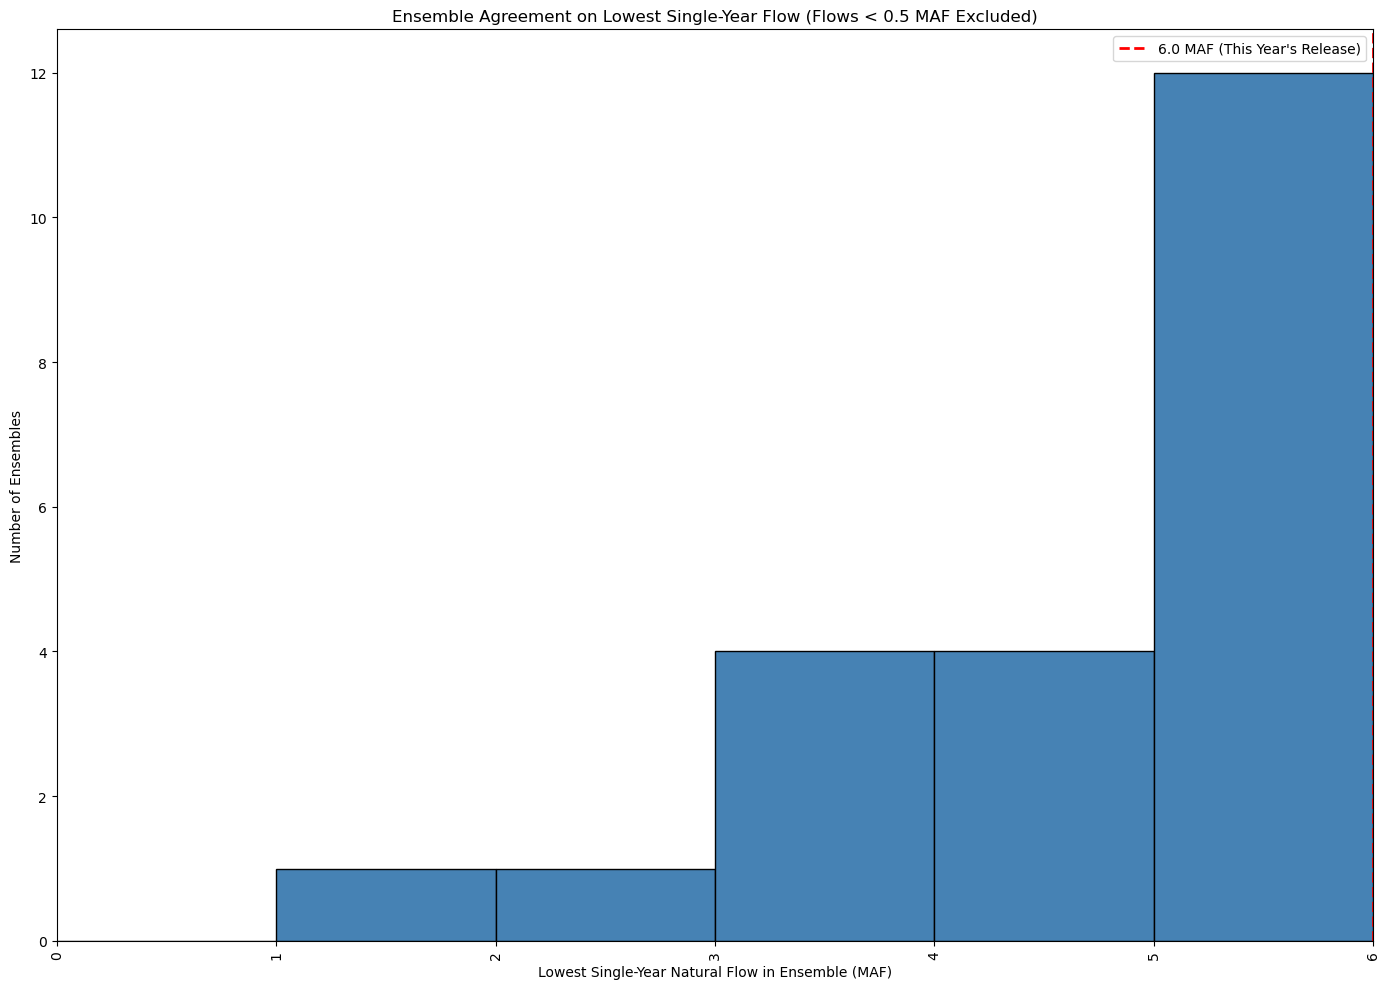

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# SETTINGS

MIN_VALID_FLOW = 0.5   # MAF; single-year flows below this are treated as unrealistic


# INPUT / OUTPUT SETUP

code_file = Path().resolve()
input_file = code_file / 'HydrologyScenarios.xlsx'
results_dir = code_file / 'Results'
results_dir.mkdir(exist_ok=True)

agreement_csv = results_dir / 'EnsembleAgreement_LowestFlowYear.csv'
counts_csv = results_dir / 'Counts_LowestFlowYear.csv'
mins_csv = results_dir / 'LowestFlowYear_ByTrace.csv'
ens_mins_csv = results_dir / 'LowestFlowYear_ByEnsemble.csv'

excluded_sheets = [
    "ReadMe", "AvailableHydrologyScenarios", "ScenarioListForAnalysis",
    "AvailableMetrics", "MetricsForAnalysis", "Heatmap", "Hist"
]

sheet_names = pd.ExcelFile(input_file).sheet_names
ensemble_sheets = [s for s in sheet_names if s not in excluded_sheets]


# LOWEST SINGLE-YEAR FLOW PER TRACE (flows below MIN_VALID_FLOW discarded)

min_records = []
num_discarded = 0

for ensemble_name in ensemble_sheets:
    df = pd.read_excel(input_file, sheet_name=ensemble_name)
    df = df.apply(pd.to_numeric, errors='coerce')

    year_col = df.columns[0]
    traces = df.columns[1:]

    for trace in traces:
        series = df[trace].dropna()

        # Discard flows below the realistic floor
        num_discarded += (series < MIN_VALID_FLOW).sum()
        series = series[series >= MIN_VALID_FLOW]

        if series.empty:
            continue

        min_idx = series.idxmin()
        min_records.append({
            'Ensemble': ensemble_name,
            'Trace': trace,
            'Year': df.loc[min_idx, year_col],
            'MinFlow': series.loc[min_idx]
        })

mins_df = pd.DataFrame(min_records)

print(f"\nFlows discarded because Flow < {MIN_VALID_FLOW} MAF: {num_discarded}")
print(f"Traces with a minimum flow: {len(mins_df)}")
print(f"Ensemble sheets found: {len(ensemble_sheets)}")
print(f"Ensembles with at least one valid flow: {mins_df['Ensemble'].nunique()}")


# ONE ROW PER ENSEMBLE: lowest single-year flow across ALL of its traces
# (each ensemble now lands in exactly one bin, so bars sum to # of ensembles)

ens_min = (
    mins_df.loc[mins_df.groupby('Ensemble')['MinFlow'].idxmin()]
    .reset_index(drop=True)
)


# DEFINE FLOW BINS

bin_width = 1.0   # change to 0.5 for finer resolution
bins = np.arange(0, np.ceil(ens_min['MinFlow'].max()) + bin_width, bin_width)
labels = [f"{b:g}" for b in bins[:-1]]

ens_min['Bin'] = pd.cut(ens_min['MinFlow'], bins=bins, labels=labels, include_lowest=True)
mins_df['Bin'] = pd.cut(mins_df['MinFlow'], bins=bins, labels=labels, include_lowest=True)


# TABLE 1: NUMBER OF ENSEMBLES PER BIN (each ensemble counted once)

agreement_mins = (
    ens_min.groupby('Bin', observed=False)
    .size()
    .reset_index(name='NumEnsembles')
)
agreement_mins['BinLeft'] = bins[:-1]

total = agreement_mins['NumEnsembles'].sum()
print(f"\nSum of bars: {total} | Ensembles included: {ens_min['Ensemble'].nunique()} "
      f"| Ensemble sheets: {len(ensemble_sheets)}")
assert total == ens_min['Ensemble'].nunique()


# TABLE 2: NUMBER OF TRACE MINIMUMS PER BIN (trace-level, for reference)

counts_mins = (
    mins_df.groupby('Bin', observed=False)
    .size()
    .reset_index(name='NumTraceMinimums')
)


# SAVE

mins_df.to_csv(mins_csv, index=False)
ens_min.to_csv(ens_mins_csv, index=False)
agreement_mins[['Bin', 'NumEnsembles']].to_csv(agreement_csv, index=False)
counts_mins.to_csv(counts_csv, index=False)

print("\nEnsemble agreement (each ensemble's lowest single-year flow):")
print(agreement_mins[['Bin', 'NumEnsembles']])

print("\nTrace-minimum counts per bin:")
print(counts_mins)

overall_min = ens_min.loc[ens_min['MinFlow'].idxmin()]
print(f"\nLowest valid flow overall: {overall_min['MinFlow']:.3f} MAF "
      f"({overall_min['Ensemble']}, {overall_min['Trace']}, year {overall_min['Year']})")

print(f"\nSaved to:\n{mins_csv}\n{ens_mins_csv}\n{agreement_csv}\n{counts_csv}")


# LOWEST YEAR FOR EACH ENSEMBLE (sorted, lowest first)

lowest_by_ensemble = (
    ens_min[['Ensemble', 'Year', 'MinFlow', 'Trace']]
    .sort_values('MinFlow')
    .reset_index(drop=True)
)
lowest_by_ensemble.index += 1  # rank starting at 1

print("\nLowest single-year flow for each ensemble (lowest first):")
print(lowest_by_ensemble.to_string(float_format=lambda x: f"{x:.3f}"))

lowest_by_ensemble.to_csv(results_dir / 'LowestYear_ByEnsemble_Sorted.csv', index_label='Rank')


# AGREE-O-GRAM

plt.figure(figsize=(14, 10))
plt.bar(
    agreement_mins['BinLeft'],
    agreement_mins['NumEnsembles'],
    width=bin_width,
    align='edge',
    color='steelblue',
    edgecolor='black'
)

plt.axvline(x=6.0, color='red', linestyle='--', linewidth=2, label="6.0 MAF (This Year's Release)")

plt.xticks(bins, [f"{b:g}" for b in bins], rotation=90)
plt.xlim(bins[0], bins[-1])
plt.xlabel("Lowest Single-Year Natural Flow in Ensemble (MAF)")
plt.ylabel("Number of Ensembles")
plt.title(f"Ensemble Agreement on Lowest Single-Year Flow (Flows < {MIN_VALID_FLOW} MAF Excluded)")
plt.legend()
plt.tight_layout()
plt.show()

In [2]:
lowest_by_ensemble = (
    ens_min[['Ensemble', 'Year', 'MinFlow', 'Trace']]
    .sort_values('MinFlow')
    .reset_index(drop=True)
)
lowest_by_ensemble.index += 1  # rank starting at 1

print("\nLowest single-year flow for each ensemble (lowest first):")
print(lowest_by_ensemble.to_string(float_format=lambda x: f"{x:.3f}"))

lowest_by_ensemble.to_csv(results_dir / 'LowestYear_ByEnsemble_Sorted.csv', index_label='Rank')


Lowest single-year flow for each ensemble (lowest first):
              Ensemble     Year  MinFlow     Trace
1                  AR1   25.000    1.115   trace63
2            RCP85_100 2100.000    2.177  trace102
3            RCP85_065 2100.000    3.217  trace102
4           CMIP5_BCSD 2047.000    3.595        25
5            RCP45_100 2092.000    3.681  trace110
6                CMIP3 2094.000    3.969   Trace53
7           CMIP5_LOCA 2096.000    4.208        50
8            RCP45_065 2092.000    4.242  trace110
9            RCP85_030 2100.000    4.344  trace102
10           RCP45_030 2092.000    4.839  trace110
11       TreeRingFlows 1685.000    5.142    Trace1
12         ISM_TRM17SK  270.000    5.142    Trace1
13       NPC_1906_2020   21.000    5.520    Trace3
14  ISM_PluvialRemoved   47.000    5.520    Trace1
15     Drought_Mid20th   12.000    5.520    Trace2
16            ISM_Full   72.000    5.520    Trace1
17       Drought_Paleo   16.000    5.611    Trace1
18    Mill_5YrBlockRes 

In [3]:
print(sheet_names)

['ReadMe', 'AvailableHydrologyScenarios', 'ScenarioListForAnalysis', 'AvailableMetrics', 'MetricsForAnalysis', 'Heatmap', 'Hist', 'ISM_Full', 'ISM_PluvialRemoved', 'ISM_StressTest', 'TreeRingFlows', 'ISM_TRM17SK', 'NPC_1906_2020', 'NPC_1988_2020', 'NPC_2000_2020', 'AR1', 'Mill_5YrBlockRes', 'Drought_Millennium', 'Drought_Mid20th', 'Drought_Paleo', 'CMIP3', 'CMIP5_LOCA', 'CMIP5_BCSD', 'RCP45_030', 'RCP45_065', 'RCP45_100', 'RCP85_030', 'RCP85_065', 'RCP85_100']


In [4]:
hist = pd.read_excel(input_file, sheet_name='Hist').apply(pd.to_numeric, errors='coerce')
year_col = hist.columns[0]

lowest3 = (
    hist.melt(id_vars=year_col, var_name='Column', value_name='Flow')
    .dropna(subset=['Flow'])
    .nsmallest(3, 'Flow')
)
print(lowest3.to_string(index=False))

  Yr Column     Flow
1977  NF_WY 5.520257
2002  NF_WY 5.933609
1934  NF_WY 6.589700



Flows discarded because Flow < 0.5 MAF: 32
Traces with a minimum flow: 2584
Ensemble sheets found: 22
Ensembles with at least one valid flow: 22

Sum of bars: 22 | Ensembles included: 22 | Ensemble sheets: 22

Ensemble agreement (each ensemble's lowest single-year flow):
  Bin  NumEnsembles  CumEnsembles
0   0             0             0
1   1             1             1
2   2             1             2
3   3             4             6
4   4             4            10
5   5            12            22
6   6             0            22
7   7             0            22
8   8             0            22

Agreement statements:
  0 of 22 ensembles agree flows could get as low as 0-1 MAF
  1 of 22 ensembles agree flows could get as low as 1-2 MAF
  2 of 22 ensembles agree flows could get as low as 2-3 MAF
  6 of 22 ensembles agree flows could get as low as 3-4 MAF
  10 of 22 ensembles agree flows could get as low as 4-5 MAF
  22 of 22 ensembles agree flows could get as low as 5-6 MAF
  

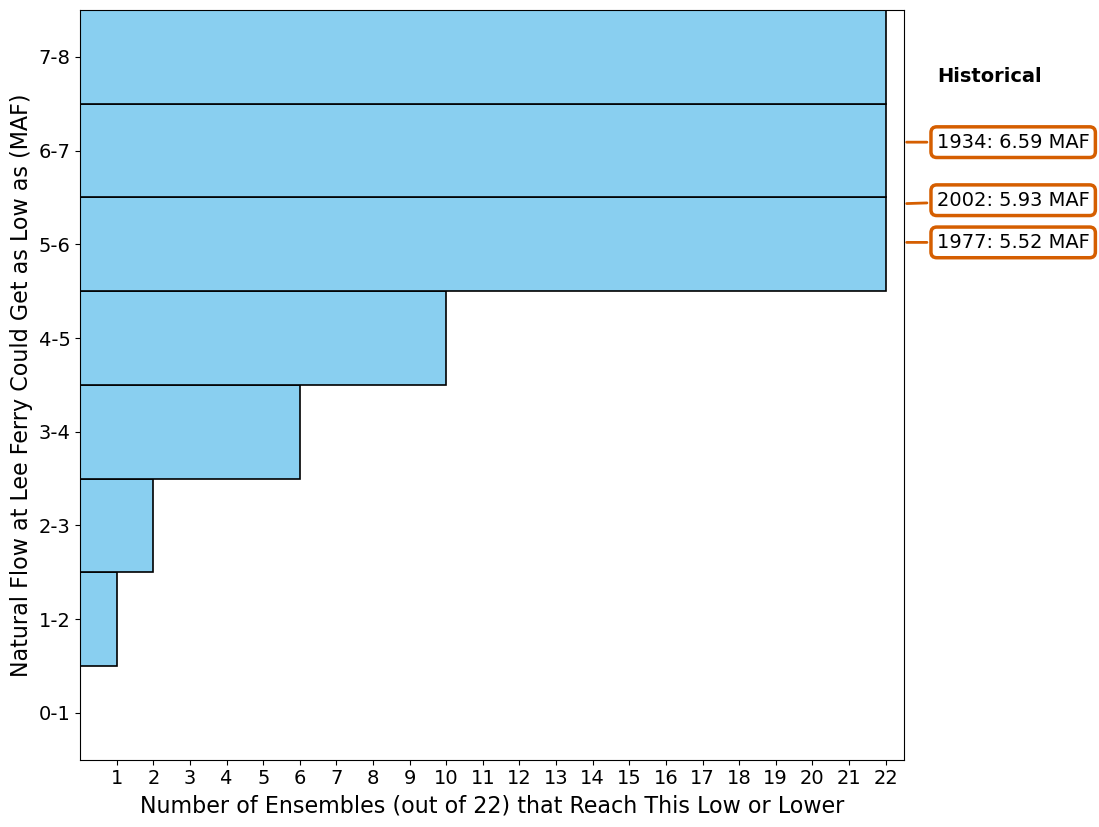

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# SETTINGS

MIN_VALID_FLOW = 0.5   # MAF; single-year flows below this are treated as unrealistic
PLOT_MAX_FLOW = 8      # top of the plotted y-axis (MAF); bins at or above this are not plotted


# INPUT / OUTPUT SETUP

code_file = Path().resolve()
input_file = code_file / 'HydrologyScenarios.xlsx'
results_dir = code_file / 'Results'
results_dir.mkdir(exist_ok=True)

agreement_csv = results_dir / 'EnsembleAgreement_LowestFlowYear.csv'
counts_csv = results_dir / 'Counts_LowestFlowYear.csv'
mins_csv = results_dir / 'LowestFlowYear_ByTrace.csv'
ens_mins_csv = results_dir / 'LowestFlowYear_ByEnsemble.csv'

excluded_sheets = [
    "ReadMe", "AvailableHydrologyScenarios", "ScenarioListForAnalysis",
    "AvailableMetrics", "MetricsForAnalysis", "Heatmap", "Hist"
]

sheet_names = pd.ExcelFile(input_file).sheet_names
ensemble_sheets = [s for s in sheet_names if s not in excluded_sheets]


# LOWEST SINGLE-YEAR FLOW PER TRACE (flows below MIN_VALID_FLOW discarded)

min_records = []
num_discarded = 0

for ensemble_name in ensemble_sheets:
    df = pd.read_excel(input_file, sheet_name=ensemble_name)
    df = df.apply(pd.to_numeric, errors='coerce')

    year_col = df.columns[0]
    traces = df.columns[1:]

    for trace in traces:
        series = df[trace].dropna()

        # Discard flows below the realistic floor
        num_discarded += (series < MIN_VALID_FLOW).sum()
        series = series[series >= MIN_VALID_FLOW]

        if series.empty:
            continue

        min_idx = series.idxmin()
        min_records.append({
            'Ensemble': ensemble_name,
            'Trace': trace,
            'Year': df.loc[min_idx, year_col],
            'MinFlow': series.loc[min_idx]
        })

mins_df = pd.DataFrame(min_records)

print(f"\nFlows discarded because Flow < {MIN_VALID_FLOW} MAF: {num_discarded}")
print(f"Traces with a minimum flow: {len(mins_df)}")
print(f"Ensemble sheets found: {len(ensemble_sheets)}")
print(f"Ensembles with at least one valid flow: {mins_df['Ensemble'].nunique()}")


# ONE ROW PER ENSEMBLE: lowest single-year flow across ALL of its traces
# (each ensemble now lands in exactly one bin, so bars sum to # of ensembles)

ens_min = (
    mins_df.loc[mins_df.groupby('Ensemble')['MinFlow'].idxmin()]
    .reset_index(drop=True)
)


# DEFINE FLOW BINS

bin_width = 1.0   # change to 0.5 for finer resolution
x_max = max(9.0, np.ceil(ens_min['MinFlow'].max()))   # bins run out to at least 9 MAF so no ensemble is dropped from the tables
bins = np.arange(0, x_max + bin_width, bin_width)
labels = [f"{b:g}" for b in bins[:-1]]

ens_min['Bin'] = pd.cut(ens_min['MinFlow'], bins=bins, labels=labels, include_lowest=True)
mins_df['Bin'] = pd.cut(mins_df['MinFlow'], bins=bins, labels=labels, include_lowest=True)


# TABLE 1: NUMBER OF ENSEMBLES PER BIN (each ensemble counted once)

agreement_mins = (
    ens_min.groupby('Bin', observed=False)
    .size()
    .reset_index(name='NumEnsembles')
)
agreement_mins['BinLeft'] = bins[:-1]

total = agreement_mins['NumEnsembles'].sum()
print(f"\nSum of bars: {total} | Ensembles included: {ens_min['Ensemble'].nunique()} "
      f"| Ensemble sheets: {len(ensemble_sheets)}")
assert total == ens_min['Ensemble'].nunique()

# CUMULATIVE: number of ensembles whose lowest flow is in this bin OR LOWER,
# i.e. ensembles that agree flows could get "as low as" this bin
n_ens = ens_min['Ensemble'].nunique()
agreement_mins['CumEnsembles'] = agreement_mins['NumEnsembles'].cumsum()


# TABLE 2: NUMBER OF TRACE MINIMUMS PER BIN (trace-level, for reference)

counts_mins = (
    mins_df.groupby('Bin', observed=False)
    .size()
    .reset_index(name='NumTraceMinimums')
)


# SAVE

mins_df.to_csv(mins_csv, index=False)
ens_min.to_csv(ens_mins_csv, index=False)
agreement_mins[['Bin', 'NumEnsembles', 'CumEnsembles']].to_csv(agreement_csv, index=False)
counts_mins.to_csv(counts_csv, index=False)

print("\nEnsemble agreement (each ensemble's lowest single-year flow):")
print(agreement_mins[['Bin', 'NumEnsembles', 'CumEnsembles']])

print("\nAgreement statements:")
for _, r in agreement_mins.iterrows():
    lo = r['BinLeft']
    print(f"  {int(r['CumEnsembles'])} of {n_ens} ensembles agree flows could get as low as {lo:g}-{lo + bin_width:g} MAF")

print("\nTrace-minimum counts per bin:")
print(counts_mins)

overall_min = ens_min.loc[ens_min['MinFlow'].idxmin()]
print(f"\nLowest valid flow overall: {overall_min['MinFlow']:.3f} MAF "
      f"({overall_min['Ensemble']}, {overall_min['Trace']}, year {overall_min['Year']})")

print(f"\nSaved to:\n{mins_csv}\n{ens_mins_csv}\n{agreement_csv}\n{counts_csv}")


# LOWEST YEAR FOR EACH ENSEMBLE (sorted, lowest first)

lowest_by_ensemble = (
    ens_min[['Ensemble', 'Year', 'MinFlow', 'Trace']]
    .sort_values('MinFlow')
    .reset_index(drop=True)
)
lowest_by_ensemble.index += 1  # rank starting at 1

print("\nLowest single-year flow for each ensemble (lowest first):")
print(lowest_by_ensemble.to_string(float_format=lambda x: f"{x:.3f}"))

lowest_by_ensemble.to_csv(results_dir / 'LowestYear_ByEnsemble_Sorted.csv', index_label='Rank')


# HISTORICAL LOWEST 3 YEARS

hist = pd.read_excel(input_file, sheet_name='Hist').apply(pd.to_numeric, errors='coerce')
hist_year_col = hist.columns[0]

lowest3 = (
    hist.melt(id_vars=hist_year_col, var_name='Column', value_name='Flow')
    .dropna(subset=['Flow'])
    .nsmallest(3, 'Flow')
)
print("\nThree lowest years in the historical record:")
print(lowest3.to_string(index=False))


# AGREE-O-GRAM (flow on the y-axis, number of ensembles on the x-axis)
# Colors chosen to stay distinguishable for colorblind readers: line styles and
# direct labels carry the meaning, not color alone.

BAR_COLOR = '#89CFF0'        # light blue
RELEASE_COLOR = '#D62728'    # red
HIST_COLOR = '#D55E00'       # vermillion (all historical lows)

# Only plot bins below the top of the axis (drops the 8-9 MAF bin and above)
plot_df = agreement_mins[agreement_mins['BinLeft'] < PLOT_MAX_FLOW]

fig, ax = plt.subplots(figsize=(14, 9))
ax.barh(
    plot_df['BinLeft'],
    plot_df['CumEnsembles'],
    height=bin_width,
    align='edge',
    color=BAR_COLOR,
    edgecolor='black',
    linewidth=1.2
)

#ax.axhline(y=6.0, color=RELEASE_COLOR, linestyle='--', linewidth=3,
#           label="6.0 MAF (This Year's Release)")

# Historical lows: dotted lines, labeled on the right-hand side of the plot.
# Label positions are nudged apart so close values don't overlap.
hist_rows = lowest3.sort_values('Flow').reset_index(drop=True)
min_gap = 0.45
label_y = []
for flow in hist_rows['Flow']:
    label_y.append(flow if not label_y else max(flow, label_y[-1] + min_gap))

for (_, row), ly in zip(hist_rows.iterrows(), label_y):
    #ax.axhline(row['Flow'], color=HIST_COLOR, linestyle=':', linewidth=3.5)
    ax.annotate(
        f"{int(row[hist_year_col])}: {row['Flow']:.2f} MAF",
        xy=(1.0, row['Flow']), xycoords=ax.get_yaxis_transform(),
        xytext=(1.04, ly), textcoords=ax.get_yaxis_transform(),
        ha='left', va='center', fontsize=14, color='black',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=HIST_COLOR, linewidth=2.5),
        arrowprops=dict(arrowstyle='-', color=HIST_COLOR, linewidth=2),
        annotation_clip=False
    )

ax.text(1.04, label_y[-1] + 0.6, "Historical", transform=ax.get_yaxis_transform(),
        ha='left', va='bottom', fontsize=14, fontweight='bold')

# Y-ticks sit at the center of each bar and are labeled with the bin's range
mid = plot_df['BinLeft'] + bin_width / 2
ax.set_yticks(mid)
ax.set_yticklabels([f"{lo:g}-{lo + bin_width:g}" for lo in plot_df['BinLeft']])
ax.set_ylim(0, PLOT_MAX_FLOW)

ax.set_xticks(np.arange(1, n_ens + 1))
ax.tick_params(labelsize=14)
ax.set_xlim(0, n_ens + 0.5)
ax.set_ylabel("Natural Flow at Lee Ferry Could Get as Low as (MAF)", fontsize=16)
ax.set_xlabel(f"Number of Ensembles (out of {n_ens}) that Reach This Low or Lower", fontsize=16)
#ax.legend(fontsize=14, loc='lower right')



fig.tight_layout(rect=(0, 0, 0.80, 0.93))   # leave room on the right for labels and on top for the title
plt.show()